# EDA general del dataset DEMUCA

Analisis de cobertura, procesamiento, anotaciones y evaluaciones DEMUCA de todas las
sesiones encontradas. Es un inventario descriptivo, no un analisis clinico ni de entrenamiento.


In [6]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd

plt.style.use('seaborn-v0_8-whitegrid')

def find_dataset_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        for candidate in (base, base / 'dataset'):
            if (candidate / 'sessions').is_dir():
                return candidate
    raise FileNotFoundError('No se encontro la raiz del dataset. Abre Jupyter desde el directorio dataset.')

def load_json(path, default):
    if not path.exists():
        return default
    with path.open(encoding='utf-8') as file:
        return json.load(file)

DATASET_ROOT = find_dataset_root()
SESSIONS_DIR = DATASET_ROOT / 'sessions'
session_dirs = sorted(path for path in SESSIONS_DIR.iterdir() if path.is_dir())
print(f'Sesiones encontradas: {len(session_dirs)}')


Sesiones encontradas: 17


## 1. Inventario de sesiones


In [7]:
rows = []
all_events = []
all_responses = []
for session_dir in session_dirs:
    session_id = session_dir.name
    metadata = load_json(session_dir / 'metadata' / 'session.json', {})
    processing = metadata.get('processing', {})
    annotation = metadata.get('annotation', {})
    technical = metadata.get('technical', {})
    event_counts = {}
    for modality in ('visual', 'audio', 'interaction'):
        events = load_json(session_dir / 'annotations' / modality / 'events.json', {'events': []}).get('events', [])
        event_counts[modality] = len(events)
        all_events.extend({'session_id': session_id, 'modality': modality, **event} for event in events)
    evaluations = load_json(session_dir / 'annotations' / 'demuca' / 'evaluations.json', {'evaluations': []}).get('evaluations', [])
    responses = evaluations[0].get('responses', []) if evaluations else []
    all_responses.extend({'session_id': session_id, **response} for response in responses)
    rows.append({
        'session_id': session_id,
        'duration_seconds': technical.get('duration_seconds'),
        'video_processed': processing.get('video_processed', False),
        'audio_processed': processing.get('audio_processed', False),
        'features_extracted': processing.get('features_extracted', False),
        'visual_events': event_counts['visual'],
        'audio_events': event_counts['audio'],
        'interaction_events': event_counts['interaction'],
        'demuca_evaluations': len(evaluations),
        'demuca_total': evaluations[0].get('total_score') if evaluations else None,
        'demuca_max': evaluations[0].get('max_total_score') if evaluations else None,
    })

sessions = pd.DataFrame(rows)
display(sessions)


,session_id,duration_seconds,video_processed,audio_processed,features_extracted,visual_events,audio_events,interaction_events,demuca_evaluations,demuca_total,demuca_max
0,S001,1440.381247,True,True,True,6,6,3,1,24,28
1,S002,1020.000000,False,False,True,5,9,6,1,21,28
2,S003,1110.000000,False,False,True,6,9,6,1,23,28
3,S004,1200.000000,False,False,True,6,4,5,1,16,28
4,S005,1290.000000,False,False,True,9,6,3,1,21,28
5,S006,840.000000,False,False,True,9,7,6,1,19,28
6,S007,930.000000,False,False,True,7,8,5,1,17,28
7,S008,1020.000000,False,False,True,6,8,5,1,22,28
8,S009,1110.000000,False,False,True,8,7,7,1,22,28
9,S010,1200.000000,False,False,True,9,5,6,1,20,28


## 2. Cobertura del pipeline


,Etapa,Sesiones
0,Video procesado,1
1,Audio procesado,1
2,Features extraidas,17
3,Con eventos,17
4,Con DEMUCA,17


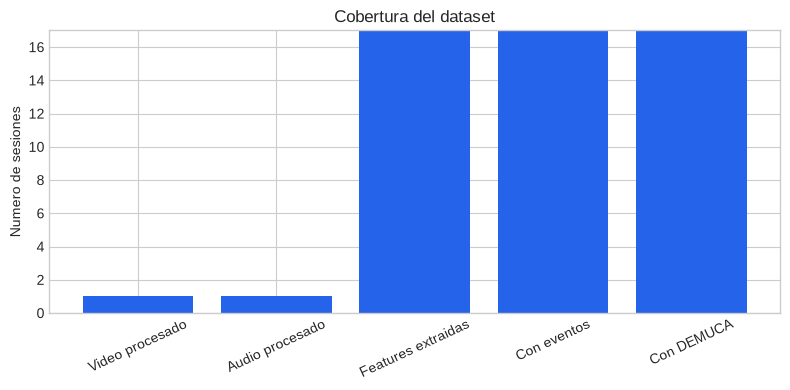

In [8]:
coverage = pd.DataFrame([
    {'Etapa': 'Video procesado', 'Sesiones': sessions['video_processed'].sum()},
    {'Etapa': 'Audio procesado', 'Sesiones': sessions['audio_processed'].sum()},
    {'Etapa': 'Features extraidas', 'Sesiones': sessions['features_extracted'].sum()},
    {'Etapa': 'Con eventos', 'Sesiones': ((sessions[['visual_events', 'audio_events', 'interaction_events']].sum(axis=1)) > 0).sum()},
    {'Etapa': 'Con DEMUCA', 'Sesiones': (sessions['demuca_evaluations'] > 0).sum()},
])
display(coverage)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(coverage['Etapa'], coverage['Sesiones'], color='#2563eb')
ax.set(title='Cobertura del dataset', ylabel='Numero de sesiones', ylim=(0, len(sessions)))
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()


## 3. Distribucion de eventos


,modality,type,eventos
0,audio,ACTIVIDAD_MUSICAL,68
4,audio,VOCALIZACION,20
1,audio,HABLA,12
2,audio,RISA,11
3,audio,SILENCIO,7
5,interaction,ACTIVIDAD_CONJUNTA,34
9,interaction,RESPUESTA,26
6,interaction,IMITACION,16
7,interaction,INTERACCION_MUSICAL,6
8,interaction,MIRADA,5


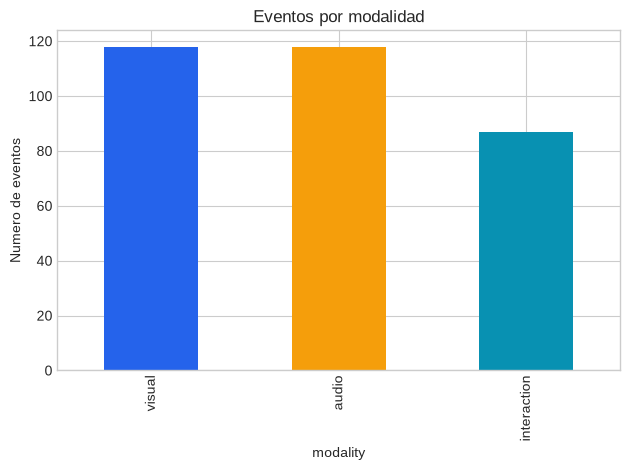

In [9]:
events = pd.DataFrame(all_events)
if events.empty:
    print('No hay eventos anotados en el dataset.')
else:
    event_summary = events.groupby(['modality', 'type']).size().rename('eventos').reset_index()
    display(event_summary.sort_values(['modality', 'eventos'], ascending=[True, False]))
    by_modality = events['modality'].value_counts()
    by_modality.plot(kind='bar', color=['#2563eb', '#f59e0b', '#0891b2'], title='Eventos por modalidad')
    plt.ylabel('Numero de eventos')
    plt.tight_layout()
    plt.show()


## 4. Evaluaciones DEMUCA disponibles


,index,category,count,mean
0,0,Comportamientos Restrictivos,51,1.058824
1,1,Exploración Vocal,51,1.588235
2,2,Interacción Social y Cognición,85,1.752941
3,3,Percepción y Exploración Rítmica,34,1.029412
4,4,Percepción y Exploración Sonora,17,1.470588


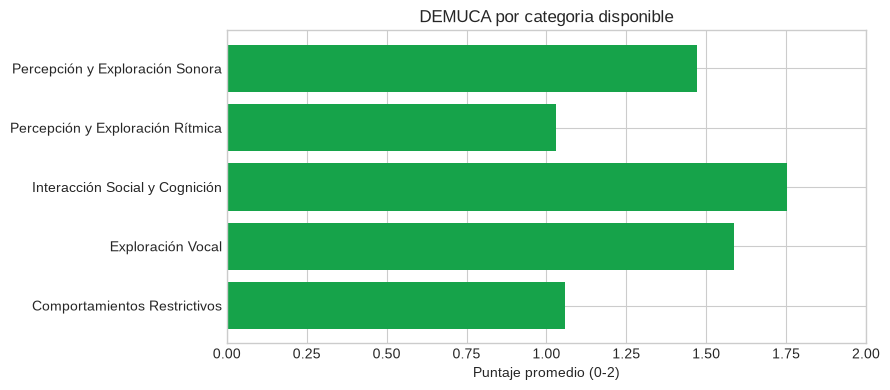

In [10]:
responses = pd.DataFrame(all_responses)
if responses.empty:
    print('No hay respuestas DEMUCA en el dataset.')
else:
    responses['score'] = pd.to_numeric(responses['score'])
    demuca_summary = responses.groupby('category', as_index=False)['score'].agg(['count', 'mean']).reset_index()
    display(demuca_summary)
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.barh(demuca_summary['category'], demuca_summary['mean'], color='#16a34a')
    ax.set(xlim=(0, 2), xlabel='Puntaje promedio (0-2)', title='DEMUCA por categoria disponible')
    plt.tight_layout()
    plt.show()
